In [1]:
from pathlib import Path
import sys

# Project root
PROJECT_ROOT = Path.cwd().parent

# Allow Python to import files from src/
sys.path.append(str(PROJECT_ROOT / "src"))

In [2]:
from data_loader import load_recording

In [3]:
PSG_PATH = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "sleep-cassette"
    / "SC4001E0-PSG.edf"
)

HYPNOGRAM_PATH = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "sleep-cassette"
    / "SC4001EC-Hypnogram.edf"
)

print("PSG:", PSG_PATH)
print("Hypnogram:", HYPNOGRAM_PATH)

PSG: d:\sscp\data\raw\sleep-cassette\SC4001E0-PSG.edf
Hypnogram: d:\sscp\data\raw\sleep-cassette\SC4001EC-Hypnogram.edf


In [4]:
print("PSG exists:", PSG_PATH.exists())
print("Hypnogram exists:", HYPNOGRAM_PATH.exists())

PSG exists: True
Hypnogram exists: True


In [4]:
raw = load_recording(
    PSG_PATH,
    HYPNOGRAM_PATH
)

d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:75: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw.set_annotations(annotations)


In [6]:
print(raw)

<RawEDF | SC4001E0-PSG.edf, 7 x 7950000 (79500.0 s), ~10 KiB, data not loaded>


In [7]:
print("Channels:")
for channel in raw.ch_names:
    print(channel)

Channels:
EEG Fpz-Cz
EEG Pz-Oz
EOG horizontal
Resp oro-nasal
EMG submental
Temp rectal
Event marker


In [8]:
print("Number of channels:", len(raw.ch_names))
print("Recording duration:", raw.times[-1], "seconds")
print("Sampling frequency:", raw.info["sfreq"], "Hz")

Number of channels: 7
Recording duration: 79499.99 seconds
Sampling frequency: 100.0 Hz


In [9]:
print(raw.info)
print("Subject info:")
print(raw.info["subject_info"])

print("\nMeasurement date:")
print(raw.info["meas_date"])

print("\nSampling frequency:")
print(raw.info["sfreq"])

<Info | 8 non-empty values
 bads: []
 ch_names: EEG Fpz-Cz, EEG Pz-Oz, EOG horizontal, Resp oro-nasal, EMG ...
 chs: 7 EEG
 custom_ref_applied: False
 highpass: 0.0 Hz
 lowpass: 50.0 Hz
 meas_date: 1989-04-24 16:13:00 UTC
 nchan: 7
 projs: []
 sfreq: 100.0 Hz
 subject_info: <subject_info | his_id: X, sex: 2, first_name: Female, last_name: 33yr>
>
Subject info:
<subject_info | his_id: X, sex: 2, first_name: Female, last_name: 33yr>

Measurement date:
1989-04-24 16:13:00+00:00

Sampling frequency:
100.0


In [10]:
print(raw.annotations)

<Annotations | 154 segments: Sleep stage 1 (24), Sleep stage 2 (40), Sleep ...>


In [11]:
print("First 20 annotations:")

for onset, duration, description in zip(
    raw.annotations.onset[:20],
    raw.annotations.duration[:20],
    raw.annotations.description[:20]
):
    print(
        f"onset={onset:.1f}s | "
        f"duration={duration:.1f}s | "
        f"stage={description}"
    )

First 20 annotations:
onset=0.0s | duration=30630.0s | stage=Sleep stage W
onset=30630.0s | duration=120.0s | stage=Sleep stage 1
onset=30750.0s | duration=390.0s | stage=Sleep stage 2
onset=31140.0s | duration=30.0s | stage=Sleep stage 3
onset=31170.0s | duration=30.0s | stage=Sleep stage 2
onset=31200.0s | duration=150.0s | stage=Sleep stage 3
onset=31350.0s | duration=30.0s | stage=Sleep stage 4
onset=31380.0s | duration=60.0s | stage=Sleep stage 3
onset=31440.0s | duration=60.0s | stage=Sleep stage 4
onset=31500.0s | duration=30.0s | stage=Sleep stage 3
onset=31530.0s | duration=120.0s | stage=Sleep stage 4
onset=31650.0s | duration=30.0s | stage=Sleep stage 3
onset=31680.0s | duration=120.0s | stage=Sleep stage 4
onset=31800.0s | duration=30.0s | stage=Sleep stage W
onset=31830.0s | duration=60.0s | stage=Sleep stage 3
onset=31890.0s | duration=60.0s | stage=Sleep stage 2
onset=31950.0s | duration=120.0s | stage=Sleep stage 3
onset=32070.0s | duration=30.0s | stage=Sleep stage 4
o

In [12]:
unique_annotations = sorted(
    set(raw.annotations.description)
)

print("Unique annotations:")

for annotation in unique_annotations:
    print(annotation)

Unique annotations:
Sleep stage 1
Sleep stage 2
Sleep stage 3
Sleep stage 4
Sleep stage ?
Sleep stage R
Sleep stage W


C:\Users\Rahini Raneru\AppData\Local\Temp\ipykernel_25024\1957726251.py:1: RuntimeWarning: Loading an EDF with mixed sampling frequencies and preload=False will result in edge artifacts. It is recommended to use preload=True.See also https://github.com/mne-tools/mne-python/issues/10635
  raw.plot(


Using matplotlib as 2D backend.
For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


C:\Users\Rahini Raneru\AppData\Local\Temp\ipykernel_25024\1957726251.py:1: RuntimeWarning: Loading an EDF with mixed sampling frequencies and preload=False will result in edge artifacts. It is recommended to use preload=True.See also https://github.com/mne-tools/mne-python/issues/10635
  raw.plot(


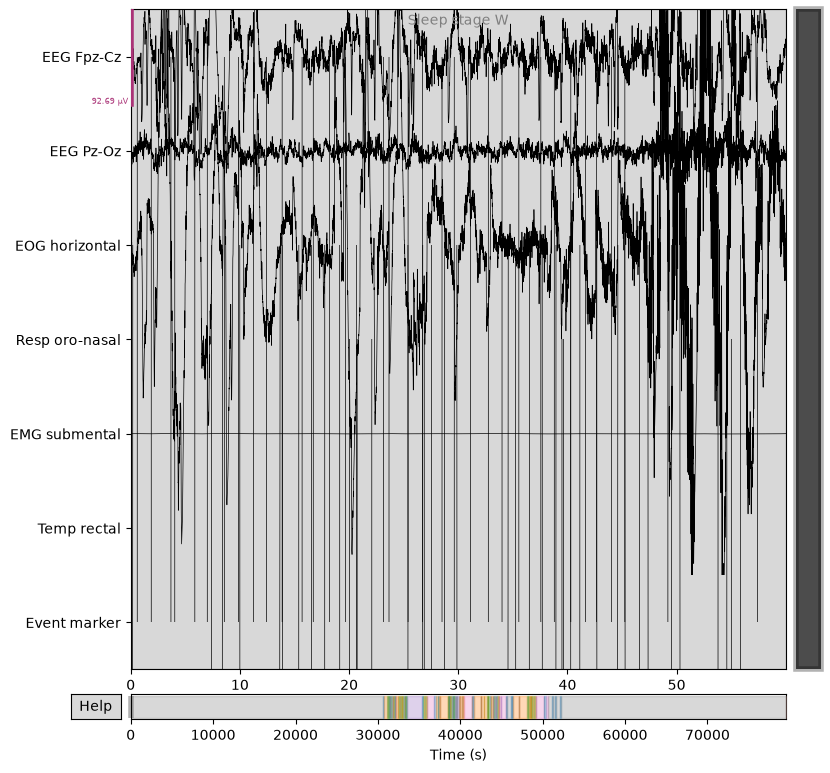

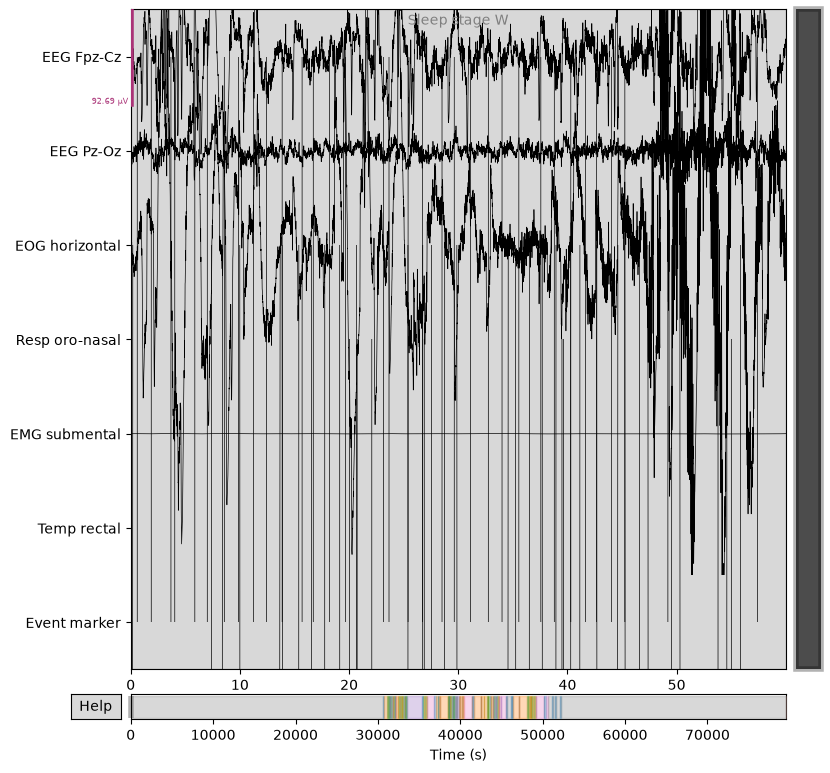

In [13]:
raw.plot(
    duration=60,
    start=0,
    scalings="auto"
)

C:\Users\Rahini Raneru\AppData\Local\Temp\ipykernel_25024\2394677303.py:1: RuntimeWarning: Loading an EDF with mixed sampling frequencies and preload=False will result in edge artifacts. It is recommended to use preload=True.See also https://github.com/mne-tools/mne-python/issues/10635
  raw.plot(


For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


C:\Users\Rahini Raneru\AppData\Local\Temp\ipykernel_25024\2394677303.py:1: RuntimeWarning: Loading an EDF with mixed sampling frequencies and preload=False will result in edge artifacts. It is recommended to use preload=True.See also https://github.com/mne-tools/mne-python/issues/10635
  raw.plot(


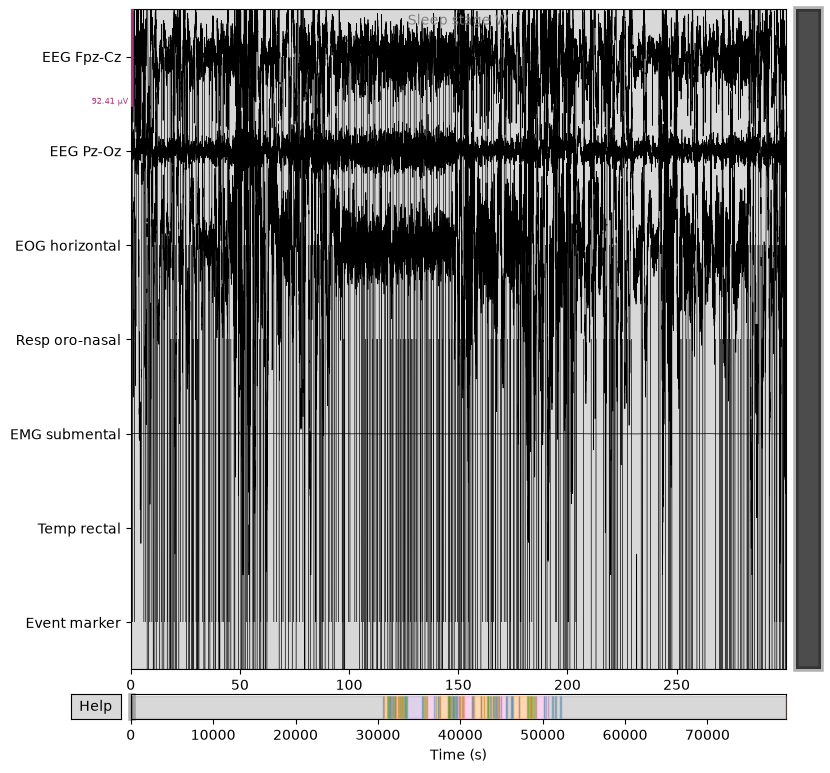

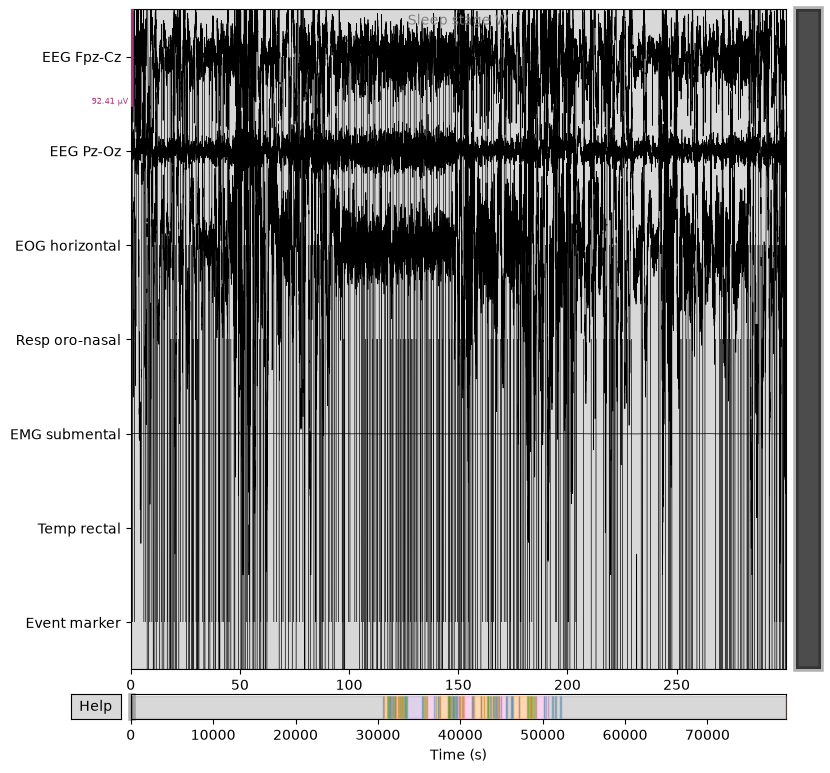

In [14]:
raw.plot(
    duration=300,
    start=0,
    scalings="auto"
)

In [6]:
from data_loader import analyze_annotations

eda_results = analyze_annotations(raw, epoch_seconds=30)

ANNOTATION EDA
Recording duration: 79,499.99 seconds
Annotation count: 154
Intended epoch length: 30 seconds

Duration alignment
Annotations whose durations are not multiples of 30s: 0

Onset alignment
Annotations whose starts are not aligned to the 30s grid: 0

Gaps and overlaps
Gaps: 0
Overlaps: 0

Stage summary
  description  annotation_count  total_duration_sec  mean_duration_sec  min_duration_sec  max_duration_sec  complete_epochs  total_duration_hours
Sleep stage W                12             59910.0        4992.500000              30.0           30630.0             1997             16.641667
Sleep stage 2                40              7500.0         187.500000              30.0             990.0              250              2.083333
Sleep stage R                 6              3750.0         625.000000             240.0             990.0              125              1.041667
Sleep stage 4                23              3570.0         155.217391              30.0            

In [7]:
eda_results["annotations"].head(20)

,onset_sec,duration_sec,description,end_sec,duration_remainder,onset_remainder,complete_epochs
0,0.0,30630.0,Sleep stage W,30630.0,0.0,0.0,1021
1,30630.0,120.0,Sleep stage 1,30750.0,0.0,0.0,4
2,30750.0,390.0,Sleep stage 2,31140.0,0.0,0.0,13
3,31140.0,30.0,Sleep stage 3,31170.0,0.0,0.0,1
4,31170.0,30.0,Sleep stage 2,31200.0,0.0,0.0,1
5,31200.0,150.0,Sleep stage 3,31350.0,0.0,0.0,5
6,31350.0,30.0,Sleep stage 4,31380.0,0.0,0.0,1
7,31380.0,60.0,Sleep stage 3,31440.0,0.0,0.0,2
8,31440.0,60.0,Sleep stage 4,31500.0,0.0,0.0,2
9,31500.0,30.0,Sleep stage 3,31530.0,0.0,0.0,1


In [8]:
eda_results["stage_summary"]

,description,annotation_count,total_duration_sec,mean_duration_sec,min_duration_sec,max_duration_sec,complete_epochs,total_duration_hours
6,Sleep stage W,12,59910.0,4992.500000,30.0,30630.0,1997,16.641667
1,Sleep stage 2,40,7500.0,187.500000,30.0,990.0,250,2.083333
5,Sleep stage R,6,3750.0,625.000000,240.0,990.0,125,1.041667
3,Sleep stage 4,23,3570.0,155.217391,30.0,1890.0,119,0.991667
2,Sleep stage 3,48,3030.0,63.125000,30.0,210.0,101,0.841667
0,Sleep stage 1,24,1740.0,72.500000,30.0,180.0,58,0.483333
4,Sleep stage ?,1,0.0,0.000000,0.0,0.0,0,0.000000


In [9]:
eda_results["gaps_and_overlaps"]

,onset_sec,end_sec,description,next_onset_sec,gap_sec,interval_type


In [10]:
eda_results["duration_misaligned"]

,onset_sec,duration_sec,description,end_sec,duration_remainder,onset_remainder,complete_epochs


In [11]:
eda_results["onset_misaligned"]

,onset_sec,duration_sec,description,end_sec,duration_remainder,onset_remainder,complete_epochs


In [13]:

import numpy as np
import pandas as pd

ann = eda_results["annotations"].copy()

recording_start = 0.0
recording_end = raw.times[-1] + 1 / raw.info["sfreq"]

print("RECORDING BOUNDARIES")
print(f"Start: {recording_start:.2f} s")
print(f"End:   {recording_end:.2f} s")

print("\nANNOTATION BOUNDARIES")
print(f"First annotation onset: {ann['onset_sec'].min():.2f} s")
print(f"Last annotation end:    {ann['end_sec'].max():.2f} s")

print("\nZERO-DURATION ANNOTATIONS")
display(
    ann.loc[
        ann["duration_sec"] <= 0,
        ["onset_sec", "duration_sec", "description", "end_sec"]
    ]
)

print("\nANNOTATIONS OUTSIDE RECORDING BOUNDS")
display(
    ann.loc[
        (ann["onset_sec"] < recording_start)
        | (ann["end_sec"] > recording_end),
        ["onset_sec", "duration_sec", "description", "end_sec"]
    ]
)

print("\nFIRST AND LAST FIVE ANNOTATIONS")
display(pd.concat([ann.head(5), ann.tail(5)]))


RECORDING BOUNDARIES
Start: 0.00 s
End:   79500.00 s

ANNOTATION BOUNDARIES
First annotation onset: 0.00 s
Last annotation end:    79500.00 s

ZERO-DURATION ANNOTATIONS


,onset_sec,duration_sec,description,end_sec
153,79500.0,0.0,Sleep stage ?,79500.0



ANNOTATIONS OUTSIDE RECORDING BOUNDS


,onset_sec,duration_sec,description,end_sec



FIRST AND LAST FIVE ANNOTATIONS


,onset_sec,duration_sec,description,end_sec,duration_remainder,onset_remainder,complete_epochs
0,0.0,30630.0,Sleep stage W,30630.0,0.0,0.0,1021
1,30630.0,120.0,Sleep stage 1,30750.0,0.0,0.0,4
2,30750.0,390.0,Sleep stage 2,31140.0,0.0,0.0,13
3,31140.0,30.0,Sleep stage 3,31170.0,0.0,0.0,1
4,31170.0,30.0,Sleep stage 2,31200.0,0.0,0.0,1
149,51540.0,30.0,Sleep stage 1,51570.0,0.0,0.0,1
150,51570.0,540.0,Sleep stage W,52110.0,0.0,0.0,18
151,52110.0,150.0,Sleep stage 1,52260.0,0.0,0.0,5
152,52260.0,27240.0,Sleep stage W,79500.0,0.0,0.0,908
153,79500.0,0.0,Sleep stage ?,79500.0,0.0,0.0,0


In [14]:
from preprocessing import build_epoch_table

epoch_table = build_epoch_table(raw, epoch_seconds=30)

print("Valid epochs:", len(epoch_table))
print("\nFirst 10 epochs:")
display(epoch_table.head(10))

print("\nEpochs per class:")
display(epoch_table["stage"].value_counts().sort_index())

print("\nEpoch durations:")
display(
    (epoch_table["end_sec"] - epoch_table["start_sec"])
    .value_counts()
)

Valid epochs: 2650

First 10 epochs:


,epoch_index,start_sec,end_sec,stage
0,0,0.0,30.0,W
1,1,30.0,60.0,W
2,2,60.0,90.0,W
3,3,90.0,120.0,W
4,4,120.0,150.0,W
5,5,150.0,180.0,W
6,6,180.0,210.0,W
7,7,210.0,240.0,W
8,8,240.0,270.0,W
9,9,270.0,300.0,W



Epochs per class:


stage
N1       58
N2      250
N3      220
REM     125
W      1997
Name: count, dtype: int64


Epoch durations:


30.0    2650
Name: count, dtype: int64

In [17]:

from pathlib import Path
from collections import defaultdict

CASSETTE_DIR = PROJECT_ROOT / "data" / "raw" / "sleep-cassette"

psg_files = sorted(CASSETTE_DIR.glob("*-PSG.edf"))
hypnogram_files = sorted(CASSETTE_DIR.glob("*-Hypnogram.edf"))

def recording_key(path):
    # Example:
    # SC4001E0-PSG.edf      -> SC4001
    # SC4001EC-Hypnogram.edf -> SC4001
    return path.name[:6]

hypnograms_by_key = defaultdict(list)

for path in hypnogram_files:
    hypnograms_by_key[recording_key(path)].append(path)

recording_pairs = []
unmatched_psg = []
ambiguous_psg = []

for psg_path in psg_files:
    matches = hypnograms_by_key.get(recording_key(psg_path), [])

    if len(matches) == 1:
        recording_pairs.append((psg_path, matches[0]))
    elif len(matches) == 0:
        unmatched_psg.append(psg_path.name)
    else:
        ambiguous_psg.append({
            "psg": psg_path.name,
            "hypnograms": [p.name for p in matches],
        })

print("PSG files:", len(psg_files))
print("Hypnogram files:", len(hypnogram_files))
print("Matched pairs:", len(recording_pairs))
print("Unmatched PSG files:", unmatched_psg)
print("Ambiguous matches:", ambiguous_psg)

for psg_path, hyp_path in recording_pairs[:10]:
    print(psg_path.name, "<->", hyp_path.name)


PSG files: 153
Hypnogram files: 153
Matched pairs: 153
Unmatched PSG files: []
Ambiguous matches: []
SC4001E0-PSG.edf <-> SC4001EC-Hypnogram.edf
SC4002E0-PSG.edf <-> SC4002EC-Hypnogram.edf
SC4011E0-PSG.edf <-> SC4011EH-Hypnogram.edf
SC4012E0-PSG.edf <-> SC4012EC-Hypnogram.edf
SC4021E0-PSG.edf <-> SC4021EH-Hypnogram.edf
SC4022E0-PSG.edf <-> SC4022EJ-Hypnogram.edf
SC4031E0-PSG.edf <-> SC4031EC-Hypnogram.edf
SC4032E0-PSG.edf <-> SC4032EP-Hypnogram.edf
SC4041E0-PSG.edf <-> SC4041EC-Hypnogram.edf
SC4042E0-PSG.edf <-> SC4042EC-Hypnogram.edf


In [ ]:
import features
from time import perf_counter

# Reload the module to pick up your latest saved code
import importlib
importlib.reload(features)

test_epochs = epoch_table.iloc[:100].copy()

start = perf_counter()

test_df = features.extract_recording_features(
    raw.copy(),
    test_epochs,
    subject_id="SC4001",
    recording_id="SC4001E0",
)

elapsed = perf_counter() - start

print(f"100 epochs took {elapsed:.2f} seconds")
print(f"Estimated full recording: {elapsed * 2650 / 100:.1f} seconds")
print(f"Output shape: {test_df.shape}")

Reading 0 ... 7949999  =      0.000 ... 79499.990 secs...
100 epochs took 1.28 seconds
Estimated full recording: 34.0 seconds
Output shape: (100, 38)


In [42]:
import importlib
import features
from time import perf_counter

importlib.reload(features)

start = perf_counter()

test_df = features.extract_recording_features(
    raw.copy(),
    epoch_table.iloc[:100].copy(),
    subject_id="SC400",
    recording_id="SC4001E0",
)

elapsed = perf_counter() - start

print(f"100 epochs: {elapsed:.2f} seconds")
print("Output shape:", test_df.shape)

100 epochs: 0.47 seconds
Output shape: (100, 38)


In [39]:
print("Recording pairs:", len(recording_pairs))
print("First three pairs:")

for psg_path, hyp_path in recording_pairs[:3]:
    print(f"{psg_path.name}  <->  {hyp_path.name}")

Recording pairs: 153
First three pairs:
SC4001E0-PSG.edf  <->  SC4001EC-Hypnogram.edf
SC4002E0-PSG.edf  <->  SC4002EC-Hypnogram.edf
SC4011E0-PSG.edf  <->  SC4011EH-Hypnogram.edf


In [43]:

import sys
import gc
import json
from pathlib import Path

import pandas as pd
from tqdm.auto import tqdm

sys.path.insert(0, str(PROJECT_ROOT / "src"))

from data_loader import load_recording
from preprocessing import build_epoch_table
from features import extract_recording_features


# Output directories
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
RECORDING_FEATURES_DIR = PROCESSED_DIR / "recording_features"

RECORDING_FEATURES_DIR.mkdir(parents=True, exist_ok=True)

FAILED_LOG = PROCESSED_DIR / "failed_recordings.json"


# Load previous failures, if any.
if FAILED_LOG.exists():
    failed_recordings = json.loads(FAILED_LOG.read_text())
else:
    failed_recordings = []


# Track failures by recording ID so reruns don't duplicate entries.
failed_by_id = {
    item["recording_id"]: item
    for item in failed_recordings
}


for psg_path, hyp_path in tqdm(
    recording_pairs,
    desc="Extracting recordings",
):
    recording_id = psg_path.stem.replace("-PSG", "")
    subject_id = psg_path.name[:5]

    output_file = (
        RECORDING_FEATURES_DIR / f"{recording_id}_features.csv"
    )

    # Resume support: completed recordings are not recomputed.
    if output_file.exists():
        continue

    raw_recording = None

    try:
        raw_recording = load_recording(psg_path, hyp_path)

        epoch_table = build_epoch_table(
            raw_recording,
            epoch_seconds=30,
        )

        if epoch_table.empty:
            raise ValueError("No valid labeled epochs found.")

        features_df = extract_recording_features(
            raw_recording,
            epoch_table,
            subject_id=subject_id,
            recording_id=recording_id,
            batch_size=256,
        )

        if features_df.empty:
            raise ValueError("Feature extraction returned no rows.")

        # Basic output integrity checks.
        if features_df["stage"].isna().any():
            raise ValueError("Missing stage labels.")

        if features_df["epoch_index"].duplicated().any():
            raise ValueError("Duplicate epoch indices.")

        numeric_columns = features_df.select_dtypes(
            include="number"
        ).columns

        if not features_df[numeric_columns].apply(
            lambda column: column.map(
                lambda value: pd.notna(value) and abs(value) != float("inf")
            )
        ).all().all():
            raise ValueError("NaN or infinite numeric feature values.")

        # Save immediately after a successful recording.
        features_df.to_csv(output_file, index=False)

        # A successful rerun clears an earlier failure entry.
        failed_by_id.pop(recording_id, None)

        print(
            f"\nSaved {recording_id}: "
            f"{len(features_df)} epochs, "
            f"{len(features_df.columns)} columns"
        )

    except Exception as exc:
        failed_by_id[recording_id] = {
            "recording_id": recording_id,
            "psg_file": psg_path.name,
            "hypnogram_file": hyp_path.name,
            "error": repr(exc),
        }

        print(f"\nFAILED: {recording_id}: {exc}")

    finally:
        if raw_recording is not None:
            del raw_recording

        gc.collect()

    # Persist the failure log after every attempted recording.
    FAILED_LOG.write_text(
        json.dumps(
            list(failed_by_id.values()),
            indent=2,
        )
    )


print("\nExtraction pass complete.")
print("Per-recording outputs:", RECORDING_FEATURES_DIR)
print("Failures:", len(failed_by_id))


Extracting recordings:   0%|          | 0/153 [00:00<?, ?it/s]


Extraction pass complete.
Per-recording outputs: d:\sscp\data\processed\recording_features
Failures: 0


In [44]:

from pathlib import Path
import pandas as pd

feature_files = sorted(
    RECORDING_FEATURES_DIR.glob("*_features.csv")
)

if not feature_files:
    raise RuntimeError("No per-recording feature files found.")

combined_path = PROCESSED_DIR / "sleep_epochs.csv"

# Verify a consistent schema before combining.
expected_columns = None

for file in feature_files:
    columns = tuple(pd.read_csv(file, nrows=0).columns)

    if expected_columns is None:
        expected_columns = columns
    elif columns != expected_columns:
        raise ValueError(f"Column mismatch in {file.name}")

# Combine the completed recordings.
dataset = pd.concat(
    [pd.read_csv(file) for file in feature_files],
    ignore_index=True,
)

dataset.to_csv(combined_path, index=False)

print("Recordings combined:", len(feature_files))
print("Dataset shape:", dataset.shape)
print("Saved to:", combined_path)


Recordings combined: 153
Dataset shape: (414961, 38)
Saved to: d:\sscp\data\processed\sleep_epochs.csv


In [45]:
print("Unique recordings:", dataset["recording_id"].nunique())
print("Unique subjects:", dataset["subject_id"].nunique())
print("Total epochs:", len(dataset))

print("\nClass distribution:")
print(dataset["stage"].value_counts())

print("\nMissing values:", dataset.isna().sum().sum())

print("\nFailures:")
print(pd.DataFrame(failed_by_id.values()))

Unique recordings: 153
Unique subjects: 153
Total epochs: 414961

Class distribution:
stage
W      285433
N2      69132
REM     25835
N1      21522
N3      13039
Name: count, dtype: int64

Missing values: 0

Failures:
Empty DataFrame
Columns: []
Index: []


In [34]:
import numpy as np
import pandas as pd

metadata_cols = [
    "subject_id",
    "recording_id",
    "epoch_index",
    "start_sec",
    "end_sec",
    "stage",
]

feature_cols = [
    col for col in dataset.columns
    if col not in metadata_cols
]

print("DATASET AUDIT")
print("=" * 50)

print("Rows:", len(dataset))
print("Columns:", len(dataset.columns))
print("Unique subjects:", dataset["subject_id"].nunique())
print("Unique recordings:", dataset["recording_id"].nunique())

print("\nClass distribution:")
print(dataset["stage"].value_counts().sort_index())

print("\nClass proportions:")
print(
    dataset["stage"].value_counts(normalize=True)
    .sort_index()
    .round(4)
)

print("\nMissing feature values:")
print(dataset[feature_cols].isna().sum().sum())

print("\nInfinite feature values:")
print(
    np.isinf(dataset[feature_cols].to_numpy(dtype=float)).sum()
)

print("\nDuplicate recording/epoch keys:")
print(
    dataset.duplicated(
        ["recording_id", "epoch_index"]
    ).sum()
)

print("\nFeature summary:")
display(dataset[feature_cols].describe().T)

DATASET AUDIT
Rows: 414961
Columns: 38
Unique subjects: 153
Unique recordings: 153

Class distribution:
stage
N1      21522
N2      69132
N3      13039
REM     25835
W      285433
Name: count, dtype: int64

Class proportions:
stage
N1     0.0519
N2     0.1666
N3     0.0314
REM    0.0623
W      0.6879
Name: proportion, dtype: float64

Missing feature values:
0

Infinite feature values:
0

Duplicate recording/epoch keys:
0

Feature summary:


,count,mean,std,min,25%,50%,75%,max
EEG Fpz-Cz_mean,414961.0,6.481989e-08,3.016883e-06,-3.371427e-05,-4.401447e-07,1.299103e-07,7.242581e-07,2.402339e-05
EEG Fpz-Cz_std,414961.0,2.313722e-05,1.231816e-05,6.666881e-07,1.352323e-05,2.113289e-05,3.033721e-05,1.315486e-04
EEG Fpz-Cz_rms,414961.0,2.330651e-05,1.236852e-05,6.767322e-07,1.364228e-05,2.128152e-05,3.055027e-05,1.317752e-04
EEG Fpz-Cz_ptp,414961.0,1.722975e-04,7.726620e-05,4.053236e-06,1.125656e-04,1.651648e-04,2.225714e-04,4.150000e-04
EEG Fpz-Cz_delta_power,414961.0,3.052088e-10,3.638836e-10,1.046963e-13,7.243119e-11,1.933111e-10,4.171933e-10,1.298460e-08
EEG Fpz-Cz_theta_power,414961.0,3.226270e-11,4.861389e-11,7.826380e-15,9.951782e-12,2.053089e-11,4.025276e-11,6.809808e-09
EEG Fpz-Cz_alpha_power,414961.0,1.290207e-11,2.235572e-11,2.430172e-15,3.946877e-12,7.767401e-12,1.491595e-11,3.875395e-09
EEG Fpz-Cz_sigma_power,414961.0,8.607248e-12,1.673246e-11,2.734726e-15,1.978000e-12,4.295428e-12,9.170845e-12,2.749507e-09
EEG Fpz-Cz_beta_power,414961.0,2.766067e-11,6.462972e-11,3.926113e-15,2.840166e-12,8.588510e-12,2.589631e-11,3.044575e-09
EEG Fpz-Cz_delta_relative,414961.0,7.569645e-01,1.546110e-01,5.577776e-02,6.882640e-01,7.987032e-01,8.689818e-01,9.886120e-01


In [46]:
# Check whether each subject has multiple recordings.
recordings_per_subject = (
    dataset.groupby("subject_id")["recording_id"]
    .nunique()
    .value_counts()
    .sort_index()
)

print("Recordings per subject:")
print(recordings_per_subject)

print("\nSample subject-recording mapping:")
display(
    dataset[["subject_id", "recording_id"]]
    .drop_duplicates()
    .sort_values(["subject_id", "recording_id"])
    .head(30)
)

Recordings per subject:
recording_id
1    153
Name: count, dtype: int64

Sample subject-recording mapping:


,subject_id,recording_id
0,SC4001,SC4001E0
2650,SC4002,SC4002E0
5479,SC4011,SC4011E0
8281,SC4012,SC4012E0
11129,SC4021,SC4021E0
13933,SC4022,SC4022E0
16688,SC4031,SC4031E0
19508,SC4032,SC4032E0
22240,SC4041,SC4041E0
24809,SC4042,SC4042E0


In [47]:
from pathlib import Path
import pandas as pd

FEATURES_DIR = Path("../data/processed/recording_features")

feature_files = sorted(FEATURES_DIR.glob("*_features.csv"))

print("Feature files found:", len(feature_files))
print("Examples:", [p.name for p in feature_files[:5]])

Feature files found: 153
Examples: ['SC4001E0_features.csv', 'SC4002E0_features.csv', 'SC4011E0_features.csv', 'SC4012E0_features.csv', 'SC4021E0_features.csv']


In [48]:
CORRECTED_DIR = FEATURES_DIR.parent / "recording_features_corrected"
CORRECTED_DIR.mkdir(parents=True, exist_ok=True)

for file in feature_files:
    df = pd.read_csv(file)

    # Each file should contain exactly one recording.
    recording_ids = df["recording_id"].dropna().unique()

    if len(recording_ids) != 1:
        raise ValueError(
            f"{file.name}: expected one recording_id, "
            f"found {len(recording_ids)}"
        )

    recording_id = recording_ids[0]
    correct_subject_id = recording_id[:5]

    # Correct metadata, not numerical features.
    df["subject_id"] = correct_subject_id

    df.to_csv(CORRECTED_DIR / file.name, index=False)

print("Corrected files:", len(list(CORRECTED_DIR.glob("*_features.csv"))))

Corrected files: 153


In [49]:
corrected_files = sorted(CORRECTED_DIR.glob("*_features.csv"))

dataset = pd.concat(
    [pd.read_csv(file) for file in corrected_files],
    ignore_index=True,
)

print("Rows:", len(dataset))
print("Unique subjects:", dataset["subject_id"].nunique())
print("Unique recordings:", dataset["recording_id"].nunique())

# Every recording must map to exactly one subject.
mapping = dataset[["subject_id", "recording_id"]].drop_duplicates()

assert mapping.groupby("recording_id")["subject_id"].nunique().max() == 1
assert (
    mapping["subject_id"] == mapping["recording_id"].str[:5]
).all()

# How many recordings does each subject have?
print("\nRecordings per subject:")
print(
    mapping.groupby("subject_id")["recording_id"]
    .nunique()
    .value_counts()
    .sort_index()
)

dataset.to_csv(
    "../data/processed/sleep_epochs_corrected.csv",
    index=False,
)

print("\nCorrected dataset saved.")

Rows: 414961
Unique subjects: 78
Unique recordings: 153

Recordings per subject:
recording_id
1     3
2    75
Name: count, dtype: int64

Corrected dataset saved.
